# IMPORTING LIBRARIES 

In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)               # Display more columns in notebook output

sns.set_theme(style="whitegrid")                         # Set a consistent chart style

# LOAD THE DATA 

In [74]:
df = pd.read_excel("Online Retail.xlsx" , engine="openpyxl")


In [75]:
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


# DATA EXPLORATION 

In [76]:
df.head()                                # # Display the first 5 rows

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [77]:
df.tail()                                # # Display the last 5 rows


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


In [78]:
df.info()                                     # Display information about columns, data types and non-null values

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [79]:
df.describe(include="all")                          # display statistical data 

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,541909.0,541909,540455,541909.000000,541909,541909.000000,406829.000000,541909
unique,25900.0,4070,4223,NaN,NaN,NaN,NaN,38
top,573585.0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,NaN,NaN,NaN,United Kingdom
freq,1114.0,2313,2369,NaN,NaN,NaN,NaN,495478
mean,NaN,NaN,NaN,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570,NaN
min,NaN,NaN,NaN,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,2011-03-28 11:34:00,1.250000,13953.000000,NaN
50%,NaN,NaN,NaN,3.000000,2011-07-19 17:17:00,2.080000,15152.000000,NaN
75%,NaN,NaN,NaN,10.000000,2011-10-19 11:27:00,4.130000,16791.000000,NaN
max,NaN,NaN,NaN,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000,NaN


In [80]:
df.isnull().sum()                             # Count missing values in each input column

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [81]:
df.duplicated().sum()                         # Count Total number of duplicate rows in each column

np.int64(5268)

In [82]:
df.columns.to_list()                          # Names of Columns in List 

['InvoiceNo',
 'StockCode',
 'Description',
 'Quantity',
 'InvoiceDate',
 'UnitPrice',
 'CustomerID',
 'Country']

In [83]:
duplicates = df[df.duplicated(keep=False)]                 # Display some Duplicates 

In [84]:
duplicates

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
...,...,...,...,...,...,...,...,...
541675,581538,22068,BLACK PIRATE TREASURE CHEST,1,2011-12-09 11:34:00,0.39,14446.0,United Kingdom
541689,581538,23318,BOX OF 6 MINI VINTAGE CRACKERS,1,2011-12-09 11:34:00,2.49,14446.0,United Kingdom
541692,581538,22992,REVOLVER WOODEN RULER,1,2011-12-09 11:34:00,1.95,14446.0,United Kingdom
541699,581538,22694,WICKER STAR,1,2011-12-09 11:34:00,2.10,14446.0,United Kingdom


# INVESTIGATE CANCELLED INVOICES AND UNUSUAL TRANSACTIONS 

In [85]:
invoice_text = df["InvoiceNo"].astype("string").str.strip()           # Convert invoice numbers to text for safe inspection

In [86]:
invoice_text

0         536365
1         536365
2         536365
3         536365
4         536365
           ...  
541904    581587
541905    581587
541906    581587
541907    581587
541908    581587
Name: InvoiceNo, Length: 541909, dtype: string

In [87]:
cancelled_mask = invoice_text.str.startswith(
    "C", na=False                                                # Identify invoice numbers beginning with C
)

In [88]:
cancelled_mask

0         False
1         False
2         False
3         False
4         False
          ...  
541904    False
541905    False
541906    False
541907    False
541908    False
Name: InvoiceNo, Length: 541909, dtype: boolean

In [89]:
cancelled_mask.sum()                         # Rows with invoice numbers beginning with C

np.int64(9288)

In [90]:
 (df["Quantity"] < 0).sum()                  # Rows with Negative Quantities

np.int64(10624)

In [91]:
(df["Quantity"] == 0).sum()                 # ROws with Zero Quantities

np.int64(0)

In [92]:
(df["UnitPrice"] == 0).sum()                # Rows with zero unit price

np.int64(2515)

In [93]:
(df["UnitPrice"] < 0).sum()                 # Rows with negative unit price

np.int64(2)

In [94]:
df.loc[
    cancelled_mask,
    ["InvoiceNo", "StockCode", "Description",            # Inspect invoice numbers beginning with C
     "Quantity", "InvoiceDate", "UnitPrice"]
].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25


# EXPLORE CUSTOMERS & COUNTRIES

In [95]:
("Unique invoice numbers:", df["InvoiceNo"].nunique())             # Unique Invoice No


('Unique invoice numbers:', 25900)

In [96]:
("Unique products:", df["StockCode"].nunique())                    # Unique products


('Unique products:', 4070)

In [97]:
("Unique customers:", df["CustomerID"].nunique())                 # Unique Customers 

('Unique customers:', 4372)

In [98]:
("Unique countries:", df["Country"].nunique())                    # Unique Contries

('Unique countries:', 38)

In [99]:
country_counts = df["Country"].value_counts()              # No of times each unique country appears


In [100]:
country_counts

Country
United Kingdom          495478
Germany                   9495
France                    8557
EIRE                      8196
Spain                     2533
Netherlands               2371
Belgium                   2069
Switzerland               2002
Portugal                  1519
Australia                 1259
Norway                    1086
Italy                      803
Channel Islands            758
Finland                    695
Cyprus                     622
Sweden                     462
Unspecified                446
Austria                    401
Denmark                    389
Japan                      358
Poland                     341
Israel                     297
USA                        291
Hong Kong                  288
Singapore                  229
Iceland                    182
Canada                     151
Greece                     146
Malta                      127
United Arab Emirates        68
European Community          61
RSA                         58


In [101]:
print(df["Description"].value_counts())            #  times each unique value appears in the "Description" Column 

Description
WHITE HANGING HEART T-LIGHT HOLDER     2369
REGENCY CAKESTAND 3 TIER               2200
JUMBO BAG RED RETROSPOT                2159
PARTY BUNTING                          1727
LUNCH BAG RED RETROSPOT                1638
                                       ... 
Missing                                   1
historic computer difference?....se       1
DUSTY PINK CHRISTMAS TREE 30CM            1
WRAP BLUE RUSSIAN FOLKART                 1
PINK BERTIE MOBILE PHONE CHARM            1
Name: count, Length: 4223, dtype: int64


In [102]:
df_eda = df.copy()                                            # Create a Copy of Dataset

df_eda["InvoiceDate"] = pd.to_datetime(
    df_eda["InvoiceDate"],                                    # Convert InvoiceDate to Datetime datatype
    errors="coerce"
)

print("Earliest transaction:", df_eda["InvoiceDate"].min())
print("Latest transaction:", df_eda["InvoiceDate"].max())

print("Invalid or missing dates:",
      df_eda["InvoiceDate"].isna().sum())

Earliest transaction: 2010-12-01 08:26:00
Latest transaction: 2011-12-09 12:50:00
Invalid or missing dates: 0


# CREATE EXPLORATORY CHARTS 

# QUANTITY DISTRIBUTION

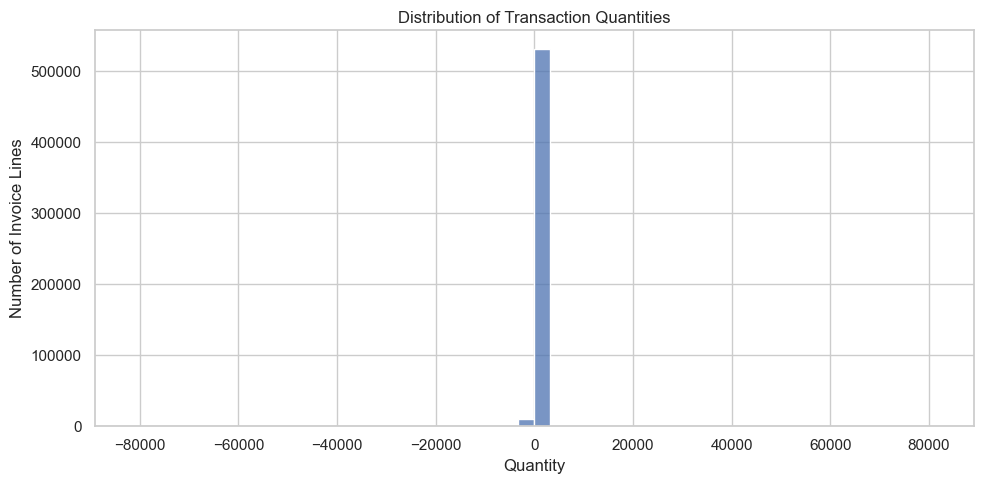

In [103]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_eda,
    x="Quantity",
    bins=50
)

plt.title("Distribution of Transaction Quantities")
plt.xlabel("Quantity")
plt.ylabel("Number of Invoice Lines")
plt.tight_layout()
plt.show()

# UNIT PRICE DISTRIBUTION 

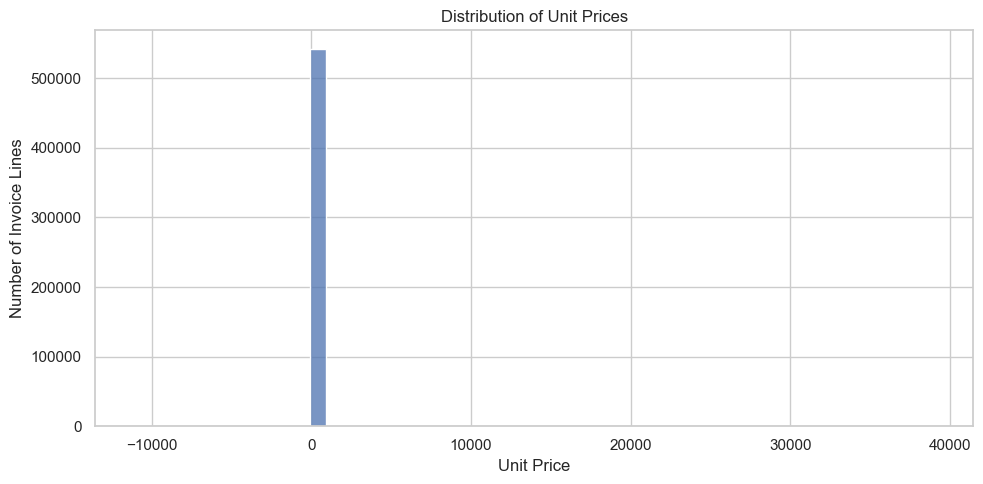

In [104]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_eda,
    x="UnitPrice",
    bins=50
)

plt.title("Distribution of Unit Prices")
plt.xlabel("Unit Price")
plt.ylabel("Number of Invoice Lines")
plt.tight_layout()
plt.show()

# TRANSACTION TREND OVER TIME 

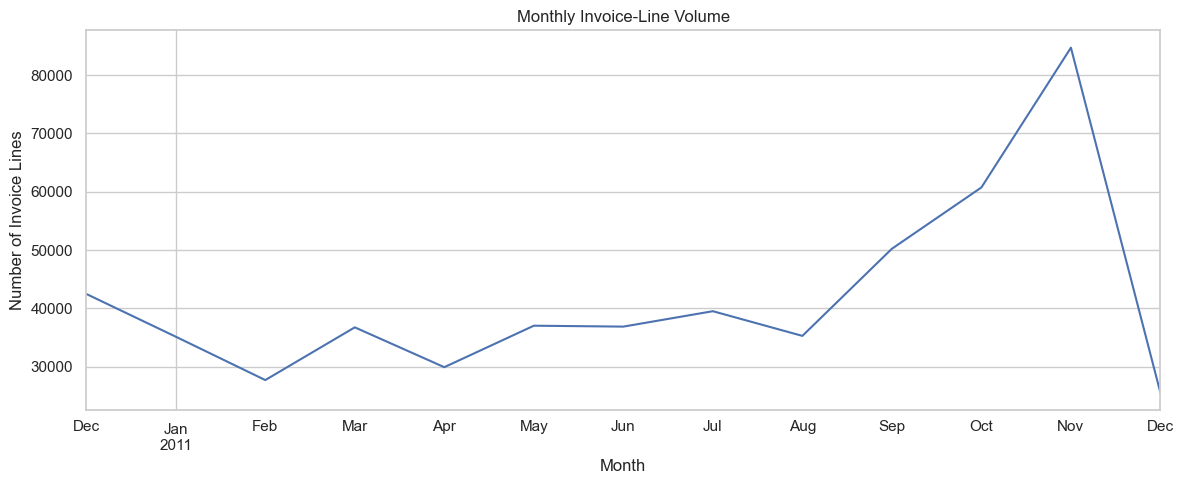

In [105]:
monthly_transactions = (
    df_eda
    .dropna(subset=["InvoiceDate"])
    .set_index("InvoiceDate")
    .resample("MS")["InvoiceNo"]
    .count()
)

plt.figure(figsize=(12, 5))

monthly_transactions.plot()

plt.title("Monthly Invoice-Line Volume")
plt.xlabel("Month")
plt.ylabel("Number of Invoice Lines")
plt.tight_layout()
plt.show()

In [106]:
eda_summary = pd.DataFrame({
    "Metric": [
        "Total rows",
        "Total columns",
        "Exact duplicate rows",
        "Missing Customer IDs",
        "Missing descriptions",
        "Missing invoice dates",
        "Unique invoice numbers",
        "Unique products",
        "Unique customers",
        "Unique countries",
        "Negative quantities",
        "Zero quantities",
        "Zero unit prices",                        # Final Summary cell to collect important data-quality metrics in one place.
        "Negative unit prices"
    ],
    "Value": [
        len(df_eda),
        df_eda.shape[1],
        df_eda.duplicated().sum(),
        df_eda["CustomerID"].isna().sum(),
        df_eda["Description"].isna().sum(),
        df_eda["InvoiceDate"].isna().sum(),
        df_eda["InvoiceNo"].nunique(),
        df_eda["StockCode"].nunique(),
        df_eda["CustomerID"].nunique(),
        df_eda["Country"].nunique(),
        (df_eda["Quantity"] < 0).sum(),
        (df_eda["Quantity"] == 0).sum(),
        (df_eda["UnitPrice"] == 0).sum(),
        (df_eda["UnitPrice"] < 0).sum()
    ]
})

eda_summary

,Metric,Value
0,Total rows,541909
1,Total columns,8
2,Exact duplicate rows,5268
3,Missing Customer IDs,135080
4,Missing descriptions,1454
5,Missing invoice dates,0
6,Unique invoice numbers,25900
7,Unique products,4070
8,Unique customers,4372
9,Unique countries,38


# DATA CLEANING & VALIDATION 

In [107]:
df_raw = df.copy(deep=True)                         # Keep the original dataset unchanged

In [110]:
df_clean = df_raw.copy(deep=True)                   # Create a separate dataset for cleaning

# CORRECT DATA TYPES

In [117]:
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"],                               # Convert invoice dates to datetime
    errors="coerce"
)

df_clean["Quantity"] = pd.to_numeric(
    df_clean["Quantity"],                                  # Convert quantities and prices to numeric values
    errors="coerce"
)

df_clean["UnitPrice"] = pd.to_numeric(
    df_clean["UnitPrice"],                                 # Convert quantities and prices to numeric values
    errors="coerce"
)

df_clean.info()                                            # Display the new data types

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


# MEASURE DUPLICATE RECORDS 

In [121]:
duplicate_count = df_clean.duplicated().sum()

print("Exact duplicate rows found:", duplicate_count)

Exact duplicate rows found: 5268


In [122]:
duplicate_rows = df_clean[
    df_clean.duplicated(keep=False)                # Preserve all rows belonging to duplicate groups for review
].copy()

In [124]:
df_clean = df_clean.drop_duplicates().copy()       # Remove repeated rows, keeping the first occurrence

# HANDLE MISSING VALUES 

In [126]:
missing_report = pd.DataFrame({
    "Missing_Count": df_clean.isna().sum(),
    "Missing_Percentage": (
        df_clean.isna().mean() * 100
    ).round(2)
})

missing_report = missing_report.sort_values(
    "Missing_Count",
    ascending=False
)

missing_report

,Missing_Count,Missing_Percentage
CustomerID,135037,25.16
Description,1454,0.27
InvoiceNo,0,0.00
StockCode,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00


In [130]:
# Display rows with missing values

rows_with_missing = df_clean[
    df_clean.isna().any(axis=1)                            
]

print("Rows containing at least one missing value:",
      len(rows_with_missing))

rows_with_missing.head(10)

Rows containing at least one missing value: 135037


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,2010-12-01 14:32:00,0.85,NaN,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,2010-12-01 14:32:00,1.66,NaN,United Kingdom
1447,536544,21790,VINTAGE SNAP CARDS,9,2010-12-01 14:32:00,1.66,NaN,United Kingdom
1448,536544,21791,VINTAGE HEADS AND TAILS CARD GAME,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1449,536544,21801,CHRISTMAS TREE DECORATION WITH BELL,10,2010-12-01 14:32:00,0.43,NaN,United Kingdom
1450,536544,21802,CHRISTMAS TREE HEART DECORATION,9,2010-12-01 14:32:00,0.43,NaN,United Kingdom
1451,536544,21803,CHRISTMAS TREE STAR DECORATION,11,2010-12-01 14:32:00,0.43,NaN,United Kingdom


# INVESTIGATE RETURN & CANCELLATON 

In [132]:
# Standardize invoice number text for inspection
invoice_text = (
    df_clean["InvoiceNo"]
    .astype("string")
    .str.strip()
)

# Create diagnostic flags
df_clean["IsCancellationInvoice"] = (
    invoice_text.str.startswith("C", na=False)
)

df_clean["IsNegativeQuantity"] = (
    df_clean["Quantity"] < 0
)

df_clean["IsZeroQuantity"] = (
    df_clean["Quantity"] == 0
)

df_clean["IsZeroPrice"] = (
    df_clean["UnitPrice"] == 0
)

df_clean["IsNegativePrice"] = (
    df_clean["UnitPrice"] < 0
)

# Summarize the records
diagnostic_columns = [
    "IsCancellationInvoice",
    "IsNegativeQuantity",
    "IsZeroQuantity",                                     
    "IsZeroPrice",
    "IsNegativePrice"
]

df_clean[diagnostic_columns].sum().sort_values(
    ascending=False
)

IsNegativeQuantity       10587
IsCancellationInvoice     9251
IsZeroPrice               2510
IsNegativePrice              2
IsZeroQuantity               0
dtype: Int64

In [133]:
df_clean.loc[
    df_clean["IsCancellationInvoice"]
    | df_clean["IsNegativeQuantity"]
    | df_clean["IsZeroPrice"]
    | df_clean["IsNegativePrice"],
    [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "InvoiceDate",
        "UnitPrice",
        "CustomerID",
        "Country"
    ]
].head(20)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom


# VALIDATE PRICE & QUANTITIES

In [134]:
validation_report = pd.DataFrame({
    "Check": [
        "Missing quantity",
        "Missing unit price",
        "Negative quantity",
        "Zero quantity",
        "Negative unit price",
        "Zero unit price",
        "Non-finite quantity",
        "Non-finite unit price"
    ],
    "Count": [
        df_clean["Quantity"].isna().sum(),
        df_clean["UnitPrice"].isna().sum(),
        (df_clean["Quantity"] < 0).sum(),
        (df_clean["Quantity"] == 0).sum(),
        (df_clean["UnitPrice"] < 0).sum(),
        (df_clean["UnitPrice"] == 0).sum(),
        (~np.isfinite(df_clean["Quantity"])).sum(),
        (~np.isfinite(df_clean["UnitPrice"])).sum()
    ]
})

validation_report

,Check,Count
0,Missing quantity,0
1,Missing unit price,0
2,Negative quantity,10587
3,Zero quantity,0
4,Negative unit price,2
5,Zero unit price,2510
6,Non-finite quantity,0
7,Non-finite unit price,0


In [135]:
df_clean["LineValue"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

df_clean["LineValue"].describe()

count    536641.000000
mean         18.123861
std         380.656263
min     -168469.600000
25%           3.750000
50%           9.870000
75%          17.400000
max      168469.600000
Name: LineValue, dtype: float64

# INVESTIGATE EXTREME VALUES 

In [138]:
# Display the 10 largest positive line values

df_clean.nlargest(
    10, "LineValue"
)[
    [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "UnitPrice",
        "LineValue",
        "Country"
    ]
]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,LineValue,Country
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60,United Kingdom
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60,United Kingdom
222680,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.00,United Kingdom
15017,537632,AMAZONFEE,AMAZON FEE,1,13541.33,13541.33,United Kingdom
299982,A563185,B,Adjust bad debt,1,11062.06,11062.06,United Kingdom
173382,551697,POST,POSTAGE,1,8142.75,8142.75,United Kingdom
348325,567423,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,7144.72,United Kingdom
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,United Kingdom
160546,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,United Kingdom
421601,573003,23084,RABBIT NIGHT LIGHT,2400,2.08,4992.00,Netherlands


# CREATE ANALYSIS READY DATASET

In [140]:
# Define valid fields for positive-sales analysis

valid_sales_mask = (
    df_clean["InvoiceDate"].notna()
    & df_clean["Quantity"].notna()
    & df_clean["UnitPrice"].notna()
    & np.isfinite(df_clean["Quantity"])
    & np.isfinite(df_clean["UnitPrice"])
    & (df_clean["Quantity"] > 0)
    & (df_clean["UnitPrice"] > 0)
    & (~df_clean["IsCancellationInvoice"])
)

df_sales = df_clean.loc[
    valid_sales_mask
].copy()

df_sales["LineValue"] = (
    df_sales["Quantity"] * df_sales["UnitPrice"]
)

print("Rows in working dataset:", len(df_clean))
print("Rows in positive-sales dataset:", len(df_sales))
print("Rows excluded from positive-sales dataset:",
      len(df_clean) - len(df_sales))

Rows in working dataset: 536641
Rows in positive-sales dataset: 524878
Rows excluded from positive-sales dataset: 11763


# VALIDATE CLEANED DATASET 

In [142]:
print("Missing dates:", df_sales["InvoiceDate"].isna().sum())
print("Missing quantities:", df_sales["Quantity"].isna().sum())
print("Missing prices:", df_sales["UnitPrice"].isna().sum())

print("Non-positive quantities:",
      (df_sales["Quantity"] <= 0).sum())

print("Non-positive prices:",
      (df_sales["UnitPrice"] <= 0).sum())

print("Duplicate rows:", df_sales.duplicated().sum())

print("\nPositive-sales data shape:", df_sales.shape)

Missing dates: 0
Missing quantities: 0
Missing prices: 0
Non-positive quantities: 0
Non-positive prices: 0
Duplicate rows: 0

Positive-sales data shape: (524878, 14)


# CREATE A BEFORE & AFTER QUALITY REPORT 

In [144]:
quality_report = pd.DataFrame({
    "Metric": [
        "Total rows",
        "Total columns",
        "Exact duplicate rows",
        "Missing CustomerID",
        "Missing Description",
        "Missing InvoiceDate",
        "Missing Quantity",
        "Missing UnitPrice",
        "Negative quantities",
        "Zero quantities",
        "Negative prices",
        "Zero prices"
    ],
    "Before_Cleaning": [
        len(df_raw),
        df_raw.shape[1],
        df_raw.duplicated().sum(),
        df_raw["CustomerID"].isna().sum(),
        df_raw["Description"].isna().sum(),
        pd.to_datetime(
            df_raw["InvoiceDate"], errors="coerce"
        ).isna().sum(),
        pd.to_numeric(
            df_raw["Quantity"], errors="coerce"
        ).isna().sum(),
        pd.to_numeric(
            df_raw["UnitPrice"], errors="coerce"
        ).isna().sum(),
        (pd.to_numeric(
            df_raw["Quantity"], errors="coerce"
        ) < 0).sum(),
        (pd.to_numeric(
            df_raw["Quantity"], errors="coerce"
        ) == 0).sum(),
        (pd.to_numeric(
            df_raw["UnitPrice"], errors="coerce"
        ) < 0).sum(),
        (pd.to_numeric(
            df_raw["UnitPrice"], errors="coerce"
        ) == 0).sum()
    ],
    "After_Cleaning": [
        len(df_clean),
        df_clean.shape[1],
        df_clean.duplicated().sum(),
        df_clean["CustomerID"].isna().sum(),
        df_clean["Description"].isna().sum(),
        df_clean["InvoiceDate"].isna().sum(),
        df_clean["Quantity"].isna().sum(),
        df_clean["UnitPrice"].isna().sum(),
        (df_clean["Quantity"] < 0).sum(),
        (df_clean["Quantity"] == 0).sum(),
        (df_clean["UnitPrice"] < 0).sum(),
        (df_clean["UnitPrice"] == 0).sum()
    ]
})

quality_report

,Metric,Before_Cleaning,After_Cleaning
0,Total rows,541909,536641
1,Total columns,8,14
2,Exact duplicate rows,5268,0
3,Missing CustomerID,135080,135037
4,Missing Description,1454,1454
5,Missing InvoiceDate,0,0
6,Missing Quantity,0,0
7,Missing UnitPrice,0,0
8,Negative quantities,10624,10587
9,Zero quantities,0,0


In [145]:
from pathlib import Path

output_folder = Path("data/processed")
output_folder.mkdir(parents=True, exist_ok=True)

df_clean.to_csv(
    output_folder / "online_retail_cleaned.csv",
    index=False
)

df_sales.to_csv(
    output_folder / "online_retail_positive_sales.csv",
    index=False
)

quality_report.to_csv(
    output_folder / "data_quality_report.csv",
    index=False
)

print("Datasets and quality report saved.")

Datasets and quality report saved.


# DATA ANALYSIS & VISUALIZATION

# PREPARE ANALYSIS DATASET

In [149]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

required = [
    "InvoiceNo", "StockCode", "Quantity",
    "InvoiceDate", "UnitPrice", "CustomerID", "Country"
]

if "df_sales" not in globals():
    raise NameError(
        "df_sales not found. Complete Phase 3 first."
    )

missing_columns = [
    col for col in required
    if col not in df_sales.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Create a separate analysis copy
sales = df_sales.copy()

sales["InvoiceDate"] = pd.to_datetime(
    sales["InvoiceDate"], errors="coerce"
)

sales["Quantity"] = pd.to_numeric(
    sales["Quantity"], errors="coerce"
)

sales["UnitPrice"] = pd.to_numeric(
    sales["UnitPrice"], errors="coerce"
)

# Calculate transaction-line revenue
sales["Revenue"] = (
    sales["Quantity"] * sales["UnitPrice"]
)

# Keep rows valid for this sales analysis
sales = sales.dropna(
    subset=["InvoiceNo", "InvoiceDate", "Quantity",
            "UnitPrice", "Country"]
)

sales = sales[
    np.isfinite(sales["Revenue"])
    & (sales["Quantity"] > 0)
    & (sales["UnitPrice"] > 0)
].copy()

print("Rows used in analysis:", len(sales))
print("Columns available:", sales.columns.tolist())
print("Date range:",
      sales["InvoiceDate"].min(),
      "to",
      sales["InvoiceDate"].max())

Rows used in analysis: 524878
Columns available: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'IsCancellationInvoice', 'IsNegativeQuantity', 'IsZeroQuantity', 'IsZeroPrice', 'IsNegativePrice', 'LineValue', 'Revenue']
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


# CALCULATE BUSINESS KPI'S

In [150]:
# Total sales value in the selected positive-sales data
total_revenue = sales["Revenue"].sum()

# Count distinct invoices
total_invoices = sales["InvoiceNo"].nunique()

# Count identifiable customers
total_customers = sales["CustomerID"].nunique()

# Count distinct products
total_products = sales["StockCode"].nunique()

# Average value per invoice
invoice_revenue = sales.groupby(
    "InvoiceNo"
)["Revenue"].sum()

average_order_value = invoice_revenue.mean()

print(f"Total revenue: {total_revenue:,.2f}")
print(f"Total invoices: {total_invoices:,}")
print(f"Identifiable customers: {total_customers:,}")
print(f"Unique products: {total_products:,}")
print(f"Average order value: {average_order_value:,.2f}")

Total revenue: 10,642,110.80
Total invoices: 19,960
Identifiable customers: 4,338
Unique products: 3,922
Average order value: 533.17


# KPI SUMMARY TABLE 

In [151]:
kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Invoices",
        "Identifiable Customers",
        "Unique Products",
        "Average Order Value"
    ],
    "Value": [
        total_revenue,
        total_invoices,
        total_customers,
        total_products,
        average_order_value
    ]
})

kpi_summary

,KPI,Value
0,Total Revenue,1.064211e+07
1,Total Invoices,1.996000e+04
2,Identifiable Customers,4.338000e+03
3,Unique Products,3.922000e+03
4,Average Order Value,5.331719e+02


# ANALYZE MONTHLY REVENUE 

In [152]:
sales["YearMonth"] = (
    sales["InvoiceDate"].dt.to_period("M")
)

monthly_revenue = (
    sales.groupby("YearMonth")["Revenue"]
    .sum()
)

monthly_revenue.index = (
    monthly_revenue.index.astype(str)
)

print(monthly_revenue)

YearMonth
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637790.330
Name: Revenue, dtype: float64


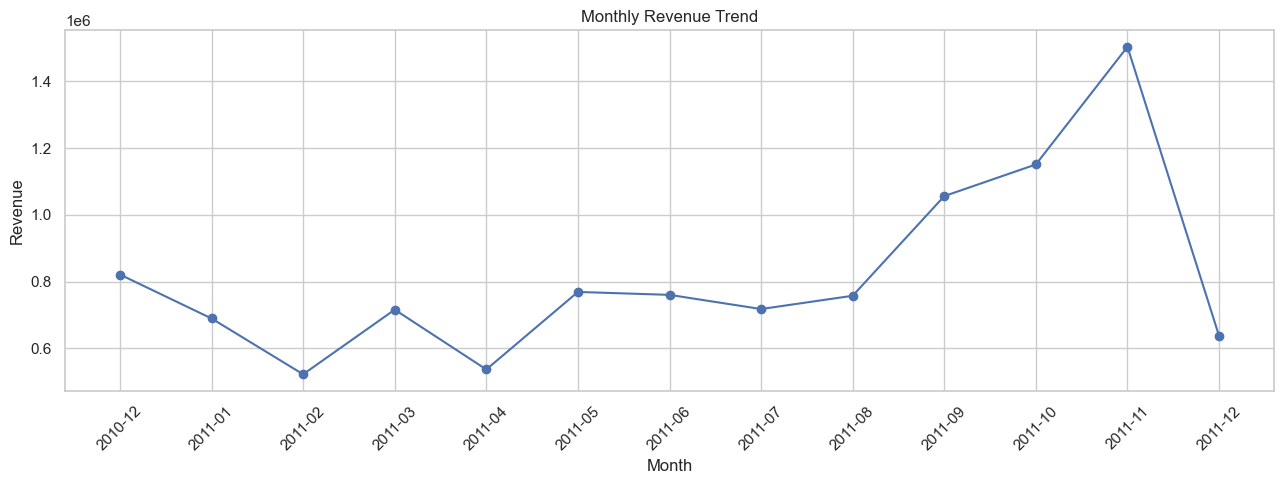

In [153]:
plt.figure(figsize=(13, 5))

plt.plot(
    monthly_revenue.index,
    monthly_revenue.values,
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ACTUAL HIGHEST & LOWEST MONTH 

In [155]:
print("Highest revenue month:")
print(monthly_revenue.idxmax(),
      round(monthly_revenue.max(), 2))

print("\nLowest revenue month:")
print(monthly_revenue.idxmin(),
      round(monthly_revenue.min(), 2))

Highest revenue month:
2011-11 1503866.78

Lowest revenue month:
2011-02 522545.56


# ANALYZE TOP SELLING PRODUCTS BY REVENUE 

In [156]:
# Group sales by product
product_revenue = (
    sales.groupby("StockCode")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

top_10_products = product_revenue.head(10)

top_10_products

StockCode
DOT       206248.77
22423     174156.54
23843     168469.60
85123A    104462.75
47566      99445.23
85099B     94159.81
23166      81700.92
POST       78101.88
M          77750.27
23084      66870.03
Name: Revenue, dtype: float64

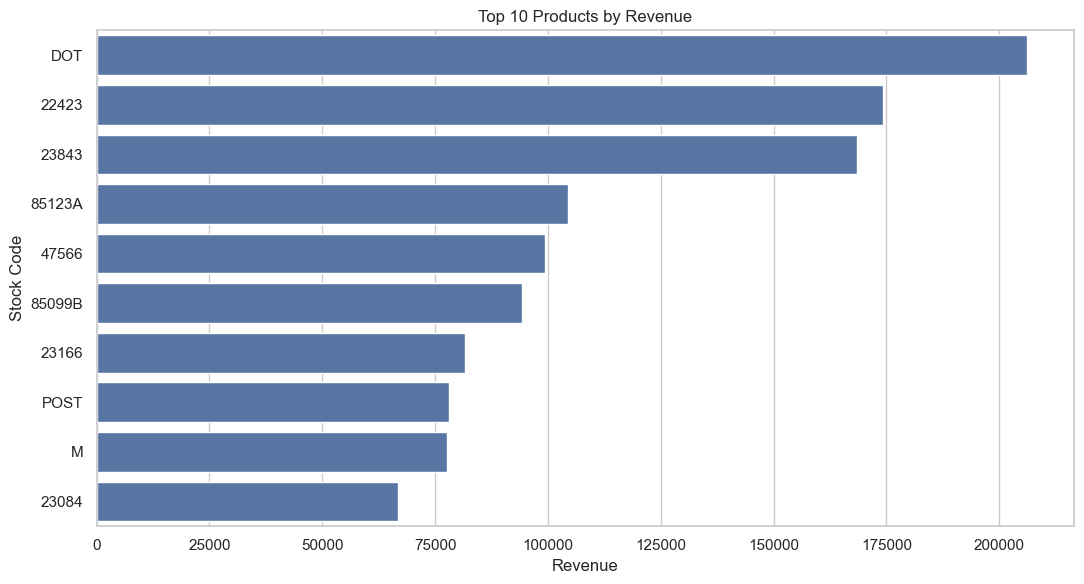

In [157]:
plt.figure(figsize=(11, 6))

sns.barplot(
    x=top_10_products.values,
    y=top_10_products.index.astype(str)
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Stock Code")
plt.tight_layout()
plt.show()

# ADD PRODUCT DESCRIPTION 

In [158]:
description_lookup = (
    sales.dropna(subset=["Description"])
    .groupby("StockCode")["Description"]
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else "Unknown")
)

top_products_table = top_10_products.rename(
    "Revenue"
).reset_index()

top_products_table["Description"] = (
    top_products_table["StockCode"]
    .map(description_lookup)
)

top_products_table[
    ["StockCode", "Description", "Revenue"]
]

,StockCode,Description,Revenue
0,DOT,DOTCOM POSTAGE,206248.77
1,22423,REGENCY CAKESTAND 3 TIER,174156.54
2,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60
3,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104462.75
4,47566,PARTY BUNTING,99445.23
5,85099B,JUMBO BAG RED RETROSPOT,94159.81
6,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92
7,POST,POSTAGE,78101.88
8,M,Manual,77750.27
9,23084,RABBIT NIGHT LIGHT,66870.03


# ANALYZE SALES BY COUNTRY 

In [159]:
country_revenue = (
    sales.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

top_countries = country_revenue.head(10)

print(top_countries)

Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64


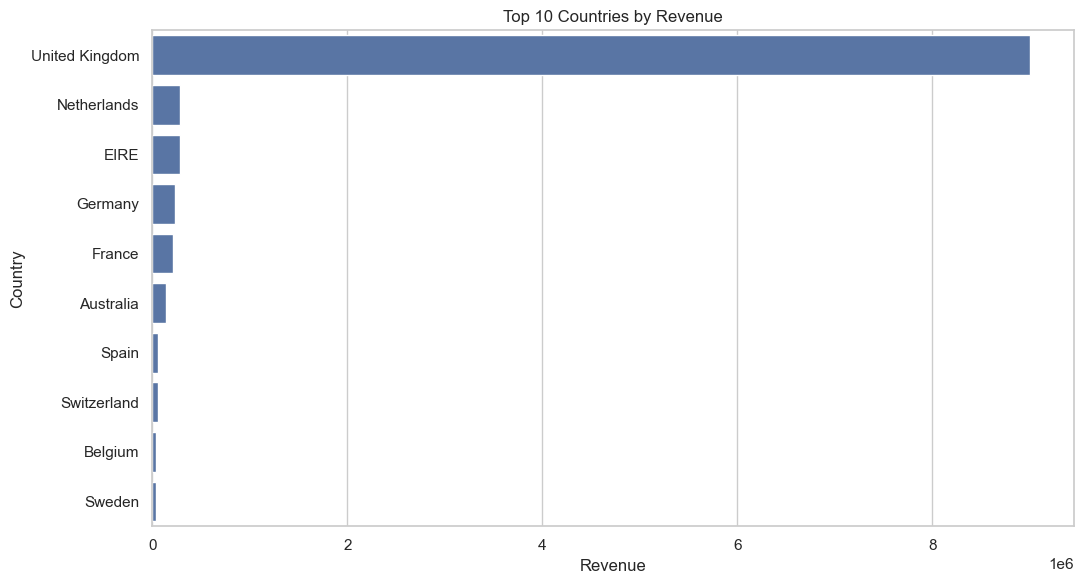

In [160]:
plt.figure(figsize=(11, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

# PERCENTAGE CONTRIBUTION OF EACH COUNTRY 

In [162]:
country_share = (
    country_revenue / country_revenue.sum() * 100
).round(2)

country_summary = pd.DataFrame({
    "Revenue": country_revenue,
    "Revenue_Percentage": country_share
})

country_summary.head(10)

,Revenue,Revenue_Percentage
Country,,
United Kingdom,9001744.094,84.59
Netherlands,285446.340,2.68
EIRE,283140.520,2.66
Germany,228678.400,2.15
France,209625.370,1.97
Australia,138453.810,1.30
Spain,61558.560,0.58
Switzerland,57067.600,0.54
Belgium,41196.340,0.39


# ANALYZE CUSTOMER PURCHASING BEHAVIOUR 

In [163]:
# Keep identifiable customers for customer analysis
customer_sales = sales.dropna(
    subset=["CustomerID"]
).copy()

reference_date = (
    customer_sales["InvoiceDate"].max()
    + pd.Timedelta(days=1)
)

customer_rfm = (
    customer_sales.groupby("CustomerID")
    .agg(
        Recency=("InvoiceDate",
                 lambda x: (reference_date - x.max()).days),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("Revenue", "sum")
    )
    .reset_index()
)

customer_rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40


# HIGHEST VALUE CUSTOMER BY REVENUE 

In [165]:
top_customers = customer_rfm.sort_values(
    "Monetary", ascending=False
).head(10)

top_customers

,CustomerID,Recency,Frequency,Monetary
1689,14646.0,2,73,280206.02
4201,18102.0,1,60,259657.30
3728,17450.0,8,46,194390.79
3008,16446.0,1,2,168472.50
1879,14911.0,1,201,143711.17
55,12415.0,24,21,124914.53
1333,14156.0,10,55,117210.08
3771,17511.0,3,31,91062.38
2702,16029.0,39,63,80850.84
0,12346.0,326,1,77183.60


# VISUALIZE CUSTOMER SPENDING 

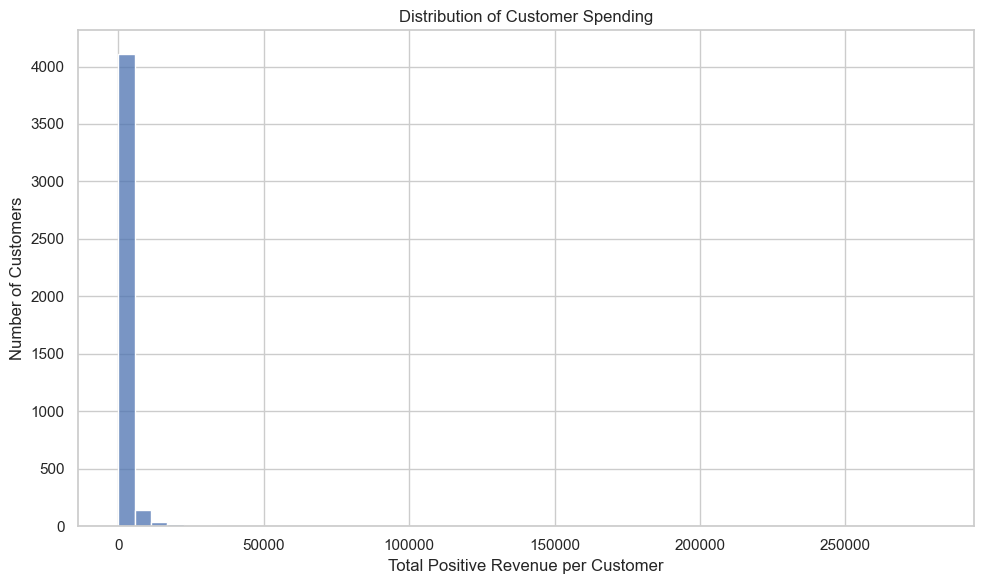

In [167]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=customer_rfm,
    x="Monetary",
    bins=50
)

plt.title("Distribution of Customer Spending")
plt.xlabel("Total Positive Revenue per Customer")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

# ANALYZE ORDER VALUE 

In [168]:
order_summary = (
    sales.groupby("InvoiceNo")
    .agg(
        OrderValue=("Revenue", "sum"),
        Units=("Quantity", "sum"),
        UniqueProducts=("StockCode", "nunique")
    )
    .reset_index()
)

order_summary.describe()

,OrderValue,Units,UniqueProducts
count,19960.000000,19960.000000,19960.000000
mean,533.171884,279.179359,26.032164
std,1780.412288,955.011810,46.982195
min,0.380000,1.000000,1.000000
25%,151.695000,69.000000,6.000000
50%,303.300000,150.000000,15.000000
75%,493.462500,296.000000,29.000000
max,168469.600000,80995.000000,1110.000000


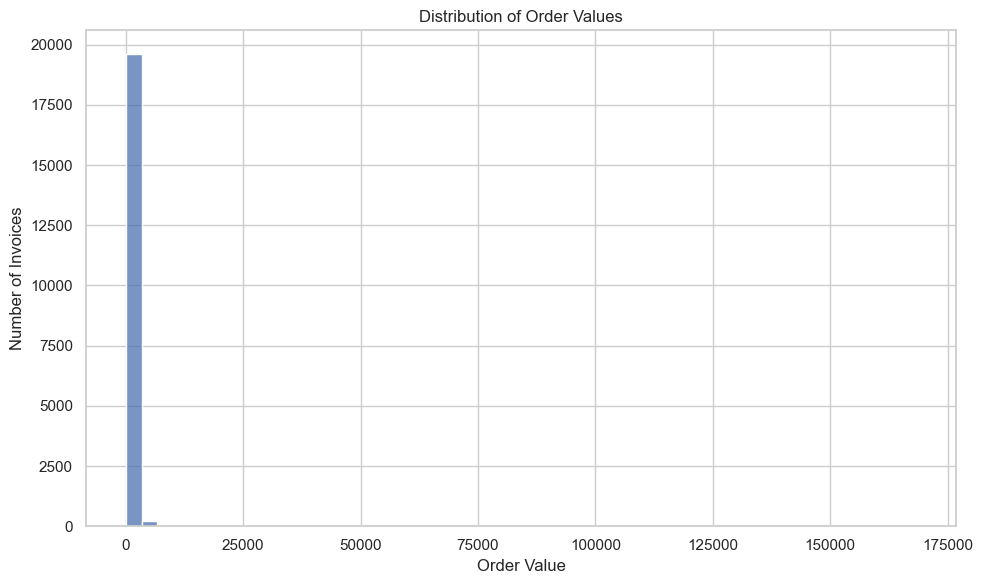

In [169]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=order_summary,
    x="OrderValue",
    bins=50
)

plt.title("Distribution of Order Values")
plt.xlabel("Order Value")
plt.ylabel("Number of Invoices")
plt.tight_layout()
plt.show()

In [171]:
order_summary["OrderValue"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

count     19960.000000
mean        533.171884
std        1780.412288
min           0.380000
25%         151.695000
50%         303.300000
75%         493.462500
90%         938.391000
95%        1585.921000
99%        4821.165400
max      168469.600000
Name: OrderValue, dtype: float64

# EXAMINE RELATION BETWEEN CUSTOMER METRICS 

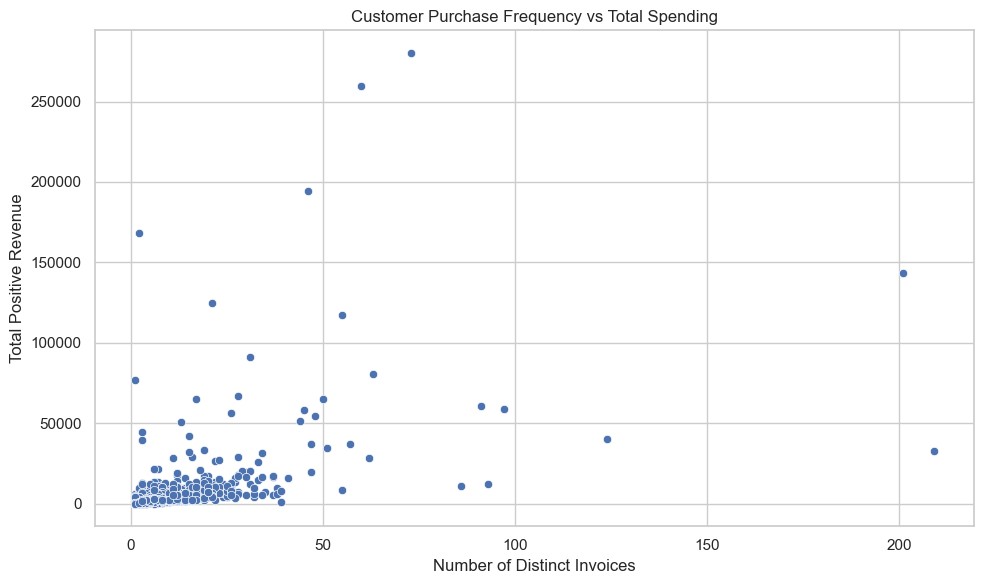

In [172]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=customer_rfm,
    x="Frequency",
    y="Monetary"
)

plt.title("Customer Purchase Frequency vs Total Spending")
plt.xlabel("Number of Distinct Invoices")
plt.ylabel("Total Positive Revenue")
plt.tight_layout()
plt.show()

# CALCULATE CORRELATION COEFFICIENT 

In [174]:
correlation = customer_rfm[
    ["Recency", "Frequency", "Monetary"]
].corr(method="spearman")

correlation

,Recency,Frequency,Monetary
Recency,1.000000,-0.562392,-0.480617
Frequency,-0.562392,1.000000,0.807185
Monetary,-0.480617,0.807185,1.000000


# SAVE ANALYSIS OUTPUT 

In [175]:
from pathlib import Path

output_dir = Path("reports/phase4")
output_dir.mkdir(parents=True, exist_ok=True)

# Save the main analytical tables
kpi_summary.to_csv(
    output_dir / "kpi_summary.csv", index=False
)

monthly_revenue.rename(
    "Revenue"
).to_csv(
    output_dir / "monthly_revenue.csv"
)

top_products_table.to_csv(
    output_dir / "top_products.csv", index=False
)

country_summary.to_csv(
    output_dir / "country_revenue.csv"
)

customer_rfm.to_csv(
    output_dir / "customer_rfm.csv", index=False
)

order_summary.to_csv(
    output_dir / "order_summary.csv", index=False
)

print("Phase 4 tables saved to:", output_dir)

Phase 4 tables saved to: reports\phase4


# STATISTICAL ANALYSIS & HYPOTHESIS TESTING 

# IMPORT LIBRARIES & PREPARE DATA 

In [176]:

# Import libraries for data analysis and statistical tests
import pandas as pd
import numpy as np
from scipy import stats
from IPython.display import display

# Make a separate copy so the original cleaned data stays unchanged
stats_df = df_sales.copy()

# Convert important columns to the correct data types
stats_df["InvoiceDate"] = pd.to_datetime(
    stats_df["InvoiceDate"], errors="coerce"
)
stats_df["Quantity"] = pd.to_numeric(
    stats_df["Quantity"], errors="coerce"
)
stats_df["UnitPrice"] = pd.to_numeric(
    stats_df["UnitPrice"], errors="coerce"
)

# Calculate revenue for each transaction line
stats_df["Revenue"] = (
    stats_df["Quantity"] * stats_df["UnitPrice"]
)

# Keep rows with valid dates and finite, positive sales values
stats_df = stats_df.dropna(
    subset=["InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice"]
).copy()

stats_df = stats_df[
    (stats_df["Quantity"] > 0) &
    (stats_df["UnitPrice"] > 0) &
    np.isfinite(stats_df["Revenue"])
].copy()

# Create a date-only column for daily analysis
stats_df["Date"] = stats_df["InvoiceDate"].dt.date

# Create weekday information: Monday = 0, Sunday = 6
stats_df["WeekdayNumber"] = stats_df["InvoiceDate"].dt.dayofweek

# Label each row as weekday or weekend
stats_df["DayType"] = np.where(
    stats_df["WeekdayNumber"] >= 5,
    "Weekend",
    "Weekday"
)

# Display the prepared data size and column names
print("Rows available for statistical analysis:", len(stats_df))
print("Columns available:", stats_df.columns.tolist())

# Display the first five rows
display(stats_df.head())


Rows available for statistical analysis: 524878
Columns available: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'IsCancellationInvoice', 'IsNegativeQuantity', 'IsZeroQuantity', 'IsZeroPrice', 'IsNegativePrice', 'LineValue', 'Revenue', 'Date', 'WeekdayNumber', 'DayType']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancellationInvoice,IsNegativeQuantity,IsZeroQuantity,IsZeroPrice,IsNegativePrice,LineValue,Revenue,Date,WeekdayNumber,DayType
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,False,False,False,False,False,15.30,15.30,2010-12-01,2,Weekday
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,False,False,False,False,20.34,20.34,2010-12-01,2,Weekday
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,False,False,False,False,False,22.00,22.00,2010-12-01,2,Weekday
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,False,False,False,False,20.34,20.34,2010-12-01,2,Weekday
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,False,False,False,False,20.34,20.34,2010-12-01,2,Weekday


# DESCRIPTIVE STATISTICAL ANALYSIS 

In [177]:

# Calculate descriptive statistics for revenue, quantity, and unit price
descriptive_stats = stats_df[
    ["Revenue", "Quantity", "UnitPrice"]
].describe().T

# Add the median because it is useful when data is skewed
descriptive_stats["median"] = stats_df[
    ["Revenue", "Quantity", "UnitPrice"]
].median()

# Display the results
display(descriptive_stats.round(2))


,count,mean,std,min,25%,50%,75%,max,median
Revenue,524878.0,20.28,271.69,0.0,3.90,9.92,17.70,168469.60,9.92
Quantity,524878.0,10.62,156.28,1.0,1.00,4.00,11.00,80995.00,4.00
UnitPrice,524878.0,3.92,36.09,0.0,1.25,2.08,4.13,13541.33,2.08


# CREATE INVOICE LEVEL DATA 

In [178]:

# Combine product lines into one record per invoice
order_stats = (
    stats_df.groupby("InvoiceNo")
    .agg(
        OrderRevenue=("Revenue", "sum"),
        OrderQuantity=("Quantity", "sum"),
        UniqueProducts=("StockCode", "nunique"),
        InvoiceDate=("InvoiceDate", "min")
    )
    .reset_index()
)

# Calculate the calendar date for each invoice
order_stats["Date"] = order_stats["InvoiceDate"].dt.date

# Display the first five orders
display(order_stats.head())

print("Number of unique invoices:", len(order_stats))


,InvoiceNo,OrderRevenue,OrderQuantity,UniqueProducts,InvoiceDate,Date
0,536365,139.12,40,7,2010-12-01 08:26:00,2010-12-01
1,536366,22.20,12,2,2010-12-01 08:28:00,2010-12-01
2,536367,278.73,83,12,2010-12-01 08:34:00,2010-12-01
3,536368,70.05,15,4,2010-12-01 08:34:00,2010-12-01
4,536369,17.85,3,1,2010-12-01 08:35:00,2010-12-01


Number of unique invoices: 19960


# HYPOTHESIS TEST 1 : WEEKDAY VS WEEKEND REVENUE 

In [179]:

# Calculate total revenue for each calendar day
daily_revenue = (
    stats_df.groupby("Date")
    .agg(
        DailyRevenue=("Revenue", "sum"),
        WeekdayNumber=("WeekdayNumber", "first")
    )
    .reset_index()
)

# Classify each calendar day
daily_revenue["DayType"] = np.where(
    daily_revenue["WeekdayNumber"] >= 5,
    "Weekend",
    "Weekday"
)

# Separate the daily revenue values into two groups
weekday_values = daily_revenue.loc[
    daily_revenue["DayType"] == "Weekday",
    "DailyRevenue"
]

weekend_values = daily_revenue.loc[
    daily_revenue["DayType"] == "Weekend",
    "DailyRevenue"
]

# Show how many observed days are in each group
print("Observed weekdays:", len(weekday_values))
print("Observed weekend days:", len(weekend_values))

# Run the test only if both groups contain enough observations
if len(weekday_values) >= 2 and len(weekend_values) >= 2:

    u_statistic, p_value = stats.mannwhitneyu(
        weekday_values,
        weekend_values,
        alternative="two-sided"
    )

    print("Mann–Whitney U statistic:", u_statistic)
    print("P-value:", p_value)

    print("Median weekday revenue:",
          round(weekday_values.median(), 2))
    print("Median weekend revenue:",
          round(weekend_values.median(), 2))

    # Interpret the result using a 5% significance level
    if p_value < 0.05:
        print(
            "Decision: Reject H0. There is statistical "
            "evidence of a difference between the groups."
        )
    else:
        print(
            "Decision: Fail to reject H0. There is insufficient "
            "evidence of a difference between the groups."
        )

else:
    print(
        "The test cannot be run reliably because one group "
        "has fewer than two observed days."
    )


Observed weekdays: 255
Observed weekend days: 50
Mann–Whitney U statistic: 11158.0
P-value: 4.968124493926503e-17
Median weekday revenue: 32630.27
Median weekend revenue: 12357.52
Decision: Reject H0. There is statistical evidence of a difference between the groups.


# HYPOTHESIS TEST 1 : ORDER QUANTITY & ORDER REVENUE 

In [180]:

# Calculate Spearman correlation between order quantity and revenue
correlation_result = stats.spearmanr(
    order_stats["OrderQuantity"],
    order_stats["OrderRevenue"]
)

spearman_rho = correlation_result.statistic
p_value = correlation_result.pvalue

print("Spearman correlation:", round(spearman_rho, 4))
print("P-value:", p_value)

if p_value < 0.05:
    print(
        "Decision: Reject H0. There is statistical evidence "
        "of a monotonic association."
    )
else:
    print(
        "Decision: Fail to reject H0. There is insufficient "
        "evidence of a monotonic association."
    )


Spearman correlation: 0.839
P-value: 0.0
Decision: Reject H0. There is statistical evidence of a monotonic association.


# HYPOTHESIS TEST 3 : IS MONTHLY REVENUE ASSOCIATED WITH TIME ?

In [181]:

# Create a monthly time period for each transaction line
stats_df["YearMonth"] = (
    stats_df["InvoiceDate"].dt.to_period("M")
)

# Calculate revenue for each month
monthly_stats = (
    stats_df.groupby("YearMonth")["Revenue"]
    .sum()
    .reset_index(name="MonthlyRevenue")
    .sort_values("YearMonth")
    .reset_index(drop=True)
)

# Assign a sequential number to each month
monthly_stats["MonthIndex"] = np.arange(
    1, len(monthly_stats) + 1
)

# Display the actual monthly results
display(monthly_stats)

# Test the association between month sequence and revenue
if len(monthly_stats) >= 3:

    trend_result = stats.spearmanr(
        monthly_stats["MonthIndex"],
        monthly_stats["MonthlyRevenue"]
    )

    rho = trend_result.statistic
    p_value = trend_result.pvalue

    print("Spearman trend coefficient:", round(rho, 4))
    print("P-value:", p_value)

    if p_value < 0.05 and rho > 0:
        print("Result: Evidence of an increasing monotonic trend.")
    elif p_value < 0.05 and rho < 0:
        print("Result: Evidence of a decreasing monotonic trend.")
    else:
        print(
            "Result: No statistically significant monotonic "
            "trend was detected."
        )

else:
    print("At least three monthly observations are needed.")


,YearMonth,MonthlyRevenue,MonthIndex
0,2010-12,821452.730,1
1,2011-01,689811.610,2
2,2011-02,522545.560,3
3,2011-03,716215.260,4
4,2011-04,536968.491,5
5,2011-05,769296.610,6
6,2011-06,760547.010,7
7,2011-07,718076.121,8
8,2011-08,757841.380,9
9,2011-09,1056435.192,10


Spearman trend coefficient: 0.3956
P-value: 0.1808891631049407
Result: No statistically significant monotonic trend was detected.


# STATISTICAL RESULT TABLE 

In [182]:

# Store the results from each hypothesis test
test_results = []

# Test 1: Weekday versus weekend
if len(weekday_values) >= 2 and len(weekend_values) >= 2:
    test_results.append({
        "Test": "Weekday vs weekend daily revenue",
        "Method": "Mann–Whitney U",
        "Statistic": u_statistic,
        "PValue": p_value if False else stats.mannwhitneyu(
            weekday_values,
            weekend_values,
            alternative="two-sided"
        ).pvalue
    })

# Test 2: Order quantity versus order revenue
test_results.append({
    "Test": "Order quantity vs order revenue",
    "Method": "Spearman correlation",
    "Statistic": spearman_rho,
    "PValue": correlation_result.pvalue
})

# Test 3: Monthly revenue trend
if len(monthly_stats) >= 3:
    test_results.append({
        "Test": "Monthly revenue trend",
        "Method": "Spearman correlation",
        "Statistic": trend_result.statistic,
        "PValue": trend_result.pvalue
    })

# Create the final table
results_table = pd.DataFrame(test_results)

# Apply the significance rule consistently
results_table["Significant at 5%"] = (
    results_table["PValue"] < 0.05
)

display(results_table.round(4))


,Test,Method,Statistic,PValue,Significant at 5%
0,Weekday vs weekend daily revenue,Mann–Whitney U,11158.0000,0.0000,True
1,Order quantity vs order revenue,Spearman correlation,0.8390,0.0000,True
2,Monthly revenue trend,Spearman correlation,0.3956,0.1809,False


In [183]:
weekday_p_value = p_value

In [184]:
weekday_p_value

np.float64(0.1808891631049407)

# SAVE THE RESULTS 

In [188]:

from pathlib import Path

# Create a folder for Phase 5 results
output_dir = Path("reports/phase5")
output_dir.mkdir(parents=True, exist_ok=True)

# Save the hypothesis-test summary
results_table.to_csv(
    output_dir / "hypothesis_test_results.csv",
    index=False
)

# Save descriptive statistics
descriptive_stats.to_csv(
    output_dir / "descriptive_statistics.csv"
)

# Save the daily and monthly summaries
daily_revenue.to_csv(
    output_dir / "daily_revenue.csv",
    index=False
)

monthly_stats.to_csv(
    output_dir / "monthly_revenue.csv",
    index=False
)

print("Phase 5 results saved to:", output_dir.resolve())


Phase 5 results saved to: C:\Users\Amaan\OneDrive\Desktop\INTERNSHIP WEEK 6\reports\phase5


# MACHINE LEARNING 

# IMPORT MACHINE LEARNING LIBRARIES 

In [190]:

# Import pandas and NumPy for working with data
import pandas as pd
import numpy as np

# Import tools for splitting data and evaluating models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Import the machine learning models
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

("Libraries imported successfully!")


'Libraries imported successfully!'

# PREPARE PREDICTION DATASET 

In [191]:

# Create a separate copy of the positive-sales data
ml_df = df_sales.copy()

# Convert columns to appropriate data types
ml_df["InvoiceDate"] = pd.to_datetime(
    ml_df["InvoiceDate"], errors="coerce"
)
ml_df["Quantity"] = pd.to_numeric(
    ml_df["Quantity"], errors="coerce"
)
ml_df["UnitPrice"] = pd.to_numeric(
    ml_df["UnitPrice"], errors="coerce"
)

# Calculate revenue for each product line
ml_df["Revenue"] = ml_df["Quantity"] * ml_df["UnitPrice"]

# Remove rows with missing or invalid required values
ml_df = ml_df.dropna(
    subset=["InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice"]
).copy()

ml_df = ml_df[
    (ml_df["Quantity"] > 0) &
    (ml_df["UnitPrice"] > 0) &
    np.isfinite(ml_df["Revenue"])
].copy()

# Create one row for each invoice
order_df = (
    ml_df.groupby("InvoiceNo")
    .agg(
        OrderRevenue=("Revenue", "sum"),
        TotalQuantity=("Quantity", "sum"),
        UniqueProducts=("StockCode", "nunique"),
        InvoiceDate=("InvoiceDate", "min")
    )
    .reset_index()
)

# Extract date and time features from the invoice date
order_df["Month"] = order_df["InvoiceDate"].dt.month
order_df["Weekday"] = order_df["InvoiceDate"].dt.dayofweek
order_df["Hour"] = order_df["InvoiceDate"].dt.hour

# Sort orders by date before splitting the data
order_df = order_df.sort_values("InvoiceDate").reset_index(drop=True)

# Display the first five orders
display(order_df.head())

print("Number of orders:", len(order_df))
print("Date range:", order_df["InvoiceDate"].min(),
      "to", order_df["InvoiceDate"].max())


,InvoiceNo,OrderRevenue,TotalQuantity,UniqueProducts,InvoiceDate,Month,Weekday,Hour
0,536365,139.12,40,7,2010-12-01 08:26:00,12,2,8
1,536366,22.20,12,2,2010-12-01 08:28:00,12,2,8
2,536367,278.73,83,12,2010-12-01 08:34:00,12,2,8
3,536368,70.05,15,4,2010-12-01 08:34:00,12,2,8
4,536369,17.85,3,1,2010-12-01 08:35:00,12,2,8


Number of orders: 19960
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


# SELECT FEATURES & TARGET 

In [192]:

# Select the input columns used to predict order revenue
feature_columns = [
    "TotalQuantity",
    "UniqueProducts",
    "Month",
    "Weekday",
    "Hour"
]

X = order_df[feature_columns]

# Select the value the model will learn to predict
y = order_df["OrderRevenue"]

print("Feature columns:", feature_columns)
print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

# Check for missing values
print("\nMissing values in features:")
display(X.isnull().sum())

print("\nMissing values in target:", y.isnull().sum())


Feature columns: ['TotalQuantity', 'UniqueProducts', 'Month', 'Weekday', 'Hour']
Feature dataset shape: (19960, 5)
Target dataset shape: (19960,)

Missing values in features:


TotalQuantity     0
UniqueProducts    0
Month             0
Weekday           0
Hour              0
dtype: int64


Missing values in target: 0


# SPLIT THE DATA INTO TRAINING & TEST SET 

In [193]:

# Find the position that separates the first 80% from the last 20%
split_index = int(len(order_df) * 0.80)

# Use earlier orders for training
X_train = X.iloc[:split_index].copy()
y_train = y.iloc[:split_index].copy()

# Use later orders for testing
X_test = X.iloc[split_index:].copy()
y_test = y.iloc[split_index:].copy()

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining period:")
print(order_df["InvoiceDate"].iloc[:split_index].min(),
      "to",
      order_df["InvoiceDate"].iloc[:split_index].max())

print("\nTesting period:")
print(order_df["InvoiceDate"].iloc[split_index:].min(),
      "to",
      order_df["InvoiceDate"].iloc[split_index:].max())


Training rows: 15968
Testing rows: 3992

Training period:
2010-12-01 08:26:00 to 2011-10-26 12:46:00

Testing period:
2011-10-26 12:48:00 to 2011-12-09 12:50:00


# TRAIN THREE MODELS 

In [194]:

# Create the baseline model
baseline_model = DummyRegressor(strategy="mean")

# Create the Linear Regression model
linear_model = LinearRegression()

# Create the Random Forest model
forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Train all three models using the training data
baseline_model.fit(X_train, y_train)
linear_model.fit(X_train, y_train)
forest_model.fit(X_train, y_train)

print("All three models have been trained!")


All three models have been trained!


# EVALUATE THE MODELS 

In [195]:

# Generate predictions for orders in the test period
baseline_predictions = baseline_model.predict(X_test)
linear_predictions = linear_model.predict(X_test)
forest_predictions = forest_model.predict(X_test)

# Define a function to calculate evaluation metrics
def evaluate_model(model_name, actual, predicted):

    # Calculate mean absolute error
    mae = mean_absolute_error(actual, predicted)

    # Calculate root mean squared error
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    # Calculate R-squared
    r2 = r2_score(actual, predicted)

    # Return the results as a dictionary
    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

# Evaluate each model on the same test set
results = [
    evaluate_model("Baseline", y_test, baseline_predictions),
    evaluate_model("Linear Regression", y_test, linear_predictions),
    evaluate_model("Random Forest", y_test, forest_predictions)
]

# Display the comparison table
model_results = pd.DataFrame(results)

# Sort by MAE: lowest error first
model_results = model_results.sort_values("MAE").reset_index(drop=True)

display(model_results.round(3))


,Model,MAE,RMSE,R2
0,Random Forest,234.580,2380.574,0.397
1,Linear Regression,249.529,1402.782,0.790
2,Baseline,515.831,3065.409,-0.001


# COMPARE ACTUAL REVENUE WITH PREDICTIVE REVENUE 

In [196]:

# Create a table with actual and predicted order revenue
prediction_comparison = pd.DataFrame({
    "ActualRevenue": y_test.to_numpy(),
    "BaselinePrediction": baseline_predictions,
    "LinearRegressionPrediction": linear_predictions,
    "RandomForestPrediction": forest_predictions
})

# Calculate Random Forest's absolute error for each order
prediction_comparison["RandomForestAbsoluteError"] = abs(
    prediction_comparison["ActualRevenue"] -
    prediction_comparison["RandomForestPrediction"]
)

# Display the first 10 predictions
display(prediction_comparison.head(10).round(2))


,ActualRevenue,BaselinePrediction,LinearRegressionPrediction,RandomForestPrediction,RandomForestAbsoluteError
0,114.74,519.19,289.20,165.00,50.26
1,219.66,519.19,353.42,324.88,105.22
2,185.11,519.19,505.64,334.61,149.50
3,184.01,519.19,370.15,253.89,69.88
4,221.97,519.19,564.68,359.08,137.11
5,124.34,519.19,176.19,149.83,25.49
6,1718.40,519.19,1252.49,996.61,721.79
7,309.76,519.19,207.70,237.49,72.27
8,327.98,519.19,408.77,395.41,67.43
9,267.13,519.19,661.85,644.58,377.45


# VISUALIZE MODEL PERFORMANCE 

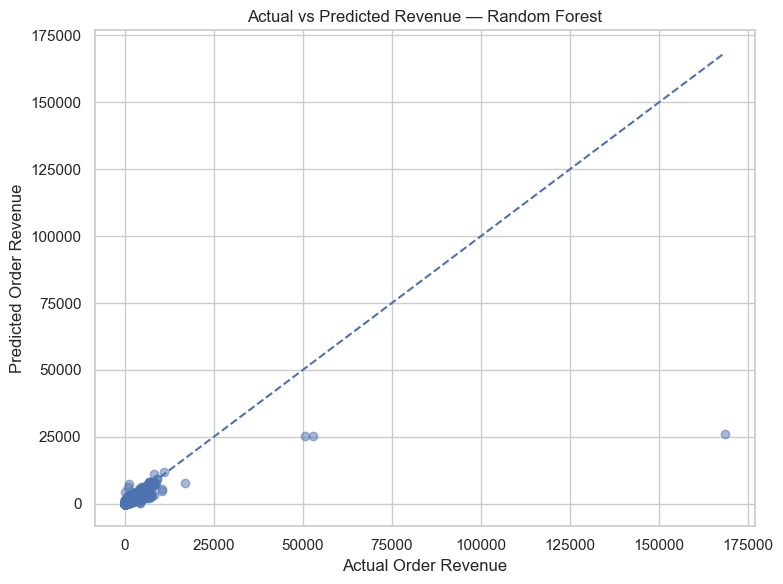

In [197]:

import matplotlib.pyplot as plt

# Plot actual versus Random Forest predicted revenue
plt.figure(figsize=(8, 6))

plt.scatter(
    prediction_comparison["ActualRevenue"],
    prediction_comparison["RandomForestPrediction"],
    alpha=0.5
)

# Add a reference line representing perfect predictions
max_value = max(
    prediction_comparison["ActualRevenue"].max(),
    prediction_comparison["RandomForestPrediction"].max()
)

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--"
)

plt.xlabel("Actual Order Revenue")
plt.ylabel("Predicted Order Revenue")
plt.title("Actual vs Predicted Revenue — Random Forest")
plt.tight_layout()
plt.show()


# SAVE MODEL RESULTS 

In [198]:

from pathlib import Path

# Create a folder for Phase 6 outputs
output_dir = Path("reports/phase6")
output_dir.mkdir(parents=True, exist_ok=True)

# Save the model comparison
model_results.to_csv(
    output_dir / "model_comparison.csv",
    index=False
)

# Save actual and predicted revenue
prediction_comparison.to_csv(
    output_dir / "revenue_predictions.csv",
    index=False
)

print("Model evaluation results saved to:", output_dir.resolve())


Model evaluation results saved to: C:\Users\Amaan\OneDrive\Desktop\INTERNSHIP WEEK 6\reports\phase6


# CONFIRM VARIABLES 

In [200]:

# Check that the required variables exist
required_variables = [
    "order_df", "X_train", "X_test",
    "y_train", "y_test", "forest_model"
]

for variable in required_variables:
    print(variable, "exists:", variable in globals())

# Check the sizes of the training and testing sets
print("\nTraining rows:", len(X_train))
print("Testing rows:", len(X_test))

# Check the date range used for training and testing
print("\nTraining date range:")
print(order_df.loc[X_train.index, "InvoiceDate"].min())
print(order_df.loc[X_train.index, "InvoiceDate"].max())

print("\nTesting date range:")
print(order_df.loc[X_test.index, "InvoiceDate"].min())
print(order_df.loc[X_test.index, "InvoiceDate"].max())


order_df exists: True
X_train exists: True
X_test exists: True
y_train exists: True
y_test exists: True
forest_model exists: True

Training rows: 15968
Testing rows: 3992

Training date range:
2010-12-01 08:26:00
2011-10-26 12:46:00

Testing date range:
2011-10-26 12:48:00
2011-12-09 12:50:00


# CREATE CROSS VALIDATION STRATEGY 

In [201]:

from sklearn.model_selection import TimeSeriesSplit

# Create five chronological cross-validation splits
time_cv = TimeSeriesSplit(n_splits=5)

# Display the training and validation sizes for each fold
for fold_number, (train_indices, val_indices) in enumerate(
    time_cv.split(X_train), start=1
):
    print(f"\nFold {fold_number}")
    print("Training rows:", len(train_indices))
    print("Validation rows:", len(val_indices))

    print(
        "Training ends at:",
        order_df.loc[X_train.index[train_indices], "InvoiceDate"].max()
    )

    print(
        "Validation runs from:",
        order_df.loc[X_train.index[val_indices], "InvoiceDate"].min(),
        "to",
        order_df.loc[X_train.index[val_indices], "InvoiceDate"].max()
    )



Fold 1
Training rows: 2663
Validation rows: 2661
Training ends at: 2011-02-01 11:19:00
Validation runs from: 2011-02-01 11:21:00 to 2011-04-04 12:54:00

Fold 2
Training rows: 5324
Validation rows: 2661
Training ends at: 2011-04-04 12:54:00
Validation runs from: 2011-04-04 12:55:00 to 2011-05-27 09:15:00

Fold 3
Training rows: 7985
Validation rows: 2661
Training ends at: 2011-05-27 09:15:00
Validation runs from: 2011-05-27 09:32:00 to 2011-07-21 13:53:00

Fold 4
Training rows: 10646
Validation rows: 2661
Training ends at: 2011-07-21 13:53:00
Validation runs from: 2011-07-21 13:54:00 to 2011-09-15 10:31:00

Fold 5
Training rows: 13307
Validation rows: 2661
Training ends at: 2011-09-15 10:31:00
Validation runs from: 2011-09-15 10:31:00 to 2011-10-26 12:46:00


# TUNE RANDOM FOREST HYPERPARAMETERS 

In [202]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV

# Create a fresh Random Forest model
rf = RandomForestRegressor(
    random_state=42,
    n_jobs=1
)

# Define the settings that we want to test
parameter_options = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10, 15, None],
    "min_samples_leaf": [2, 5, 10],
    "max_features": [0.8, 1.0]
}

# Set up the search using chronological cross-validation
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=parameter_options,
    n_iter=12,
    scoring="neg_mean_absolute_error",
    cv=time_cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

# Train and compare the sampled parameter combinations
random_search.fit(X_train, y_train)

print("\nBest hyperparameters:")
print(random_search.best_params_)

print(
    "\nBest cross-validation MAE:",
    round(-random_search.best_score_, 3)
)


Fitting 5 folds for each of 12 candidates, totalling 60 fits

Best hyperparameters:
{'n_estimators': 200, 'min_samples_leaf': 5, 'max_features': 0.8, 'max_depth': 15}

Best cross-validation MAE: 197.477


# INSPECT BEST MODELS & TUNING RESULTS 

In [206]:

# Get the best model fitted by the search
best_rf_model = random_search.best_estimator_

# Convert all tuning results into a DataFrame
cv_results = pd.DataFrame(random_search.cv_results_)

# Keep the most useful columns
cv_results = cv_results[
    [
        "rank_test_score",
        "mean_test_score",
        "std_test_score",
        "mean_train_score",
        "params"
    ]
].copy()

# Convert negative MAE scores to positive MAE values
cv_results["CV_MAE"] = -cv_results["mean_test_score"]
cv_results["Train_MAE"] = -cv_results["mean_train_score"]

# Sort by the best cross-validation MAE
cv_results = cv_results.sort_values("CV_MAE")

# Display the best five configurations
display(cv_results.head(5).round(3))


,rank_test_score,mean_test_score,std_test_score,mean_train_score,params,CV_MAE,Train_MAE
0,1,-197.477,20.858,-156.561,"{'n_estimators': 200, 'min_samples_leaf': 5, '...",197.477,156.561
2,2,-198.250,21.166,-157.395,"{'n_estimators': 100, 'min_samples_leaf': 5, '...",198.250,157.395
9,3,-200.570,21.885,-123.946,"{'n_estimators': 200, 'min_samples_leaf': 2, '...",200.570,123.946
6,4,-200.897,20.713,-152.089,"{'n_estimators': 100, 'min_samples_leaf': 2, '...",200.897,152.089
4,5,-201.265,21.482,-124.649,"{'n_estimators': 100, 'min_samples_leaf': 2, '...",201.265,124.649


# COMPARE THE ORIGINAL & TUNED MODEL 

In [207]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Generate predictions from the original Random Forest
original_predictions = forest_model.predict(X_test)

# Generate predictions from the tuned Random Forest
tuned_predictions = best_rf_model.predict(X_test)

# Define a reusable evaluation function
def calculate_metrics(model_name, actual, predicted):

    return {
        "Model": model_name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "R2": r2_score(actual, predicted)
    }

# Evaluate both models and the original baseline if available
comparison = [
    calculate_metrics(
        "Original Random Forest",
        y_test,
        original_predictions
    ),
    calculate_metrics(
        "Tuned Random Forest",
        y_test,
        tuned_predictions
    )
]

if "baseline_predictions" in globals():
    comparison.append(
        calculate_metrics(
            "Baseline",
            y_test,
            baseline_predictions
        )
    )

# Display the comparison
improved_results = pd.DataFrame(comparison)
improved_results = improved_results.sort_values("MAE")

display(improved_results.round(3))


,Model,MAE,RMSE,R2
0,Original Random Forest,234.580,2380.574,0.397
1,Tuned Random Forest,235.375,2424.843,0.374
2,Baseline,515.831,3065.409,-0.001


# EXAMINE ERRORS IN TUNED MODEL 

In [208]:

# Create a test-set prediction table
tuned_prediction_table = pd.DataFrame({
    "ActualRevenue": y_test.to_numpy(),
    "PredictedRevenue": tuned_predictions
})

# Calculate signed and absolute prediction errors
tuned_prediction_table["Error"] = (
    tuned_prediction_table["ActualRevenue"] -
    tuned_prediction_table["PredictedRevenue"]
)

tuned_prediction_table["AbsoluteError"] = (
    tuned_prediction_table["Error"].abs()
)

# Display examples of predictions
display(tuned_prediction_table.head(10).round(2))

# Display the orders with the largest absolute errors
display(
    tuned_prediction_table
    .sort_values("AbsoluteError", ascending=False)
    .head(10)
    .round(2)
)


,ActualRevenue,PredictedRevenue,Error,AbsoluteError
0,114.74,160.69,-45.95,45.95
1,219.66,309.50,-89.84,89.84
2,185.11,302.37,-117.26,117.26
3,184.01,228.06,-44.05,44.05
4,221.97,343.23,-121.26,121.26
5,124.34,158.08,-33.74,33.74
6,1718.40,1023.47,694.93,694.93
7,309.76,247.72,62.04,62.04
8,327.98,370.52,-42.54,42.54
9,267.13,693.60,-426.47,426.47


,ActualRevenue,PredictedRevenue,Error,AbsoluteError
3956,168469.60,23939.87,144529.73,144529.73
956,52940.94,22790.36,30150.58,30150.58
1612,50653.91,22790.36,27863.55,27863.55
388,16874.58,7486.57,9388.01,9388.01
83,1146.96,7366.83,-6219.87,6219.87
2541,10584.77,4847.45,5737.32,5737.32
2466,8124.25,2931.08,5193.17,5193.17
2748,7483.83,2349.52,5134.31,5134.31
3938,10363.82,5447.53,4916.29,4916.29
2703,6778.73,2009.28,4769.45,4769.45


In [209]:

from pathlib import Path
import joblib

# Create the output folder
output_dir = Path("reports/phase7")
output_dir.mkdir(parents=True, exist_ok=True)

# Save the comparison table
improved_results.to_csv(
    output_dir / "model_improvement_comparison.csv",
    index=False
)

# Save the cross-validation search results
cv_results.to_csv(
    output_dir / "hyperparameter_search_results.csv",
    index=False
)

# Save the tuned model
joblib.dump(
    best_rf_model,
    output_dir / "tuned_random_forest.joblib"
)

# Save test-set predictions and errors
tuned_prediction_table.to_csv(
    output_dir / "tuned_model_predictions.csv",
    index=False
)

print("Tuned model and results saved in:", output_dir.resolve())


Tuned model and results saved in: C:\Users\Amaan\OneDrive\Desktop\INTERNSHIP WEEK 6\reports\phase7
